# 01 · Exploratory data analysis

Partitions: **TRAIN** (80 trips) and **STUDENT_TEST** (10 trips). The evaluator partition is never read (the loader blocks it).

This notebook only calls repo code: `scripts/inventory.py`, `scripts/eda.py`, `scripts/make_maps.py` and the `pathsnap` library. Decisions and reasoning are in `docs/data_quality_log.md`.

In [1]:
import subprocess, sys
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, IFrame, display
from pathsnap.config import repo_path
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
RES, FIG = repo_path("experiments/results"), repo_path("experiments/figures")

def run(script, *args):
    """Run a repo script exactly as from the command line (outputs land in experiments/)."""
    out = subprocess.run([sys.executable, str(repo_path(script)), *args], capture_output=True, text=True, check=True)
    print(out.stdout[-3000:])

## 1. Inventory
One row per trip: file sizes, observation counts, GPS validity, timing, network and route structure.

In [2]:
run("scripts/inventory.py")
inv = pd.read_csv(RES / "inventory.csv", dtype={"trip_id": str})
inv.head()

[train] 80 trips found
[student_test] 10 trips found

Wrote /home/pqtl/ML-Hackathon-148-2026/experiments/results/inventory.csv (90 trips)

partition            student_test     train
n_obs         count          10.0      80.0
              mean         1916.0    2605.2
              std          1335.4    3312.3
              min           262.0     361.0
              25%           917.8     945.8
              50%          1420.0    1529.0
              75%          2872.0    2792.8
              max          3958.0   19313.0
duration_s    count          10.0      80.0
              mean         2025.0    5680.4
              std          1311.7   18252.2
              min           265.0     451.0
              25%          1040.0    1225.3
              50%          1809.5    1710.0
              75%          2871.2    3765.0
              max          4000.0  154030.0
path_length_m count          10.0      80.0
              mean        29696.8   37230.2
              std        

,partition,trip_id,has_track,track_bytes,has_nodes,nodes_bytes,has_arcs,arcs_bytes,has_route,route_bytes,n_obs,n_nan_rows,n_out_of_range,n_zero_coords,t_monotonic,...,n_arcs,arcs_bad_node_ref,self_loops,duplicate_arcs,frac_arcs_with_reverse,isolated_nodes,n_weak_components,largest_wcc_frac,n_strong_components,largest_scc_frac,route_len,route_unique_arcs,route_invalid_ids,route_consecutive_connected_frac,route_repeated_consecutive
0,train,00000001,True,40975,True,1687371,True,1948474,True,3119,1315,0,0,0,True,...,165790,0,0,292,0.818819,0,175,0.977986,1942,0.957099,525,525,0,1.000000,0
1,train,00000002,True,238085,True,158720,True,156519,True,1398,7243,0,0,0,True,...,16139,0,0,0,0.996964,0,14,0.976562,14,0.976562,262,262,0,0.996169,0
2,train,00000003,True,26164,True,182760,True,175733,True,411,821,0,0,0,True,...,18028,0,0,6,0.909807,0,42,0.943861,167,0.901182,79,79,0,1.000000,0
3,train,00000004,True,34982,True,147000,True,149738,True,1582,1064,0,0,0,True,...,15499,0,0,5,0.975611,0,12,0.986939,14,0.986667,320,320,0,1.000000,0
4,train,00000005,True,33378,True,17960,True,12351,True,421,1045,0,0,0,True,...,1579,0,0,0,0.815706,0,3,0.988864,153,0.635857,105,105,0,1.000000,0


In [3]:
run("scripts/eda.py")
pd.read_csv(RES / "eda_partition_summary.csv").set_index("partition").T

Analysing 90 trips on all cores ...
                           0          1
partition       student_test      train
trips                     10         80
obs_total              19160     208417
obs_min                  262        361
obs_median            1420.0     1529.0
obs_max                 3958      19313
track_mb            0.625911   6.872352
nodes_mb            1.822179  38.431647
arcs_mb             1.902157  44.267751
route_kb              18.344    165.702
missing_files              0          0
nan_rows                   0          0
out_of_range               0          0
zero_coords                0          0
dup_timestamps             0          0
backwards_time             0          0
gaps_gt_5s                44       1216
max_gap_s              210.0   153064.0
jumps_gt_60mps             2        546
nodes_median          6596.5     9608.0
arcs_median          13145.0    19526.5
arcs_max               56027     307392

gaps>5s: 1260 rows; jumps>60m/s: 548 rows; 

partition,student_test,train
trips,10.000000,80.000000
obs_total,19160.000000,208417.000000
obs_min,262.000000,361.000000
obs_median,1420.000000,1529.000000
obs_max,3958.000000,19313.000000
track_mb,0.625911,6.872352
nodes_mb,1.822179,38.431647
arcs_mb,1.902157,44.267751
route_kb,18.344000,165.702000
missing_files,0.000000,0.000000


## 2. One trip, raw
File formats: `.track` = lon lat t, `.nodes` = lon lat (row = node id), `.arcs` = from to (row = arc id), `.route` = arc ids in order.

In [4]:
from pathsnap.io import discover_trips, load_trip
from pathsnap.geo import TripGeometry
trip = load_trip(discover_trips("train")["00000072"], with_route=True)
print(trip.track.dtypes.to_dict(), trip.nodes.shape, trip.arcs.shape, trip.route[:10])
geom = TripGeometry.from_trip(trip)
print("UTM EPSG", geom.proj.epsg, "| arc length median %.1f m" % np.median(geom.arc_lengths()))
trip.track.head()

{'lon': dtype('float64'), 'lat': dtype('float64'), 't': dtype('float64')} (3275, 2) (7063, 2) [6091 6097 6095 4537 1352 3149 3153 3151 3147  344]
UTM EPSG 32637 | arc length median 24.0 m


,lon,lat,t
obs_idx,,,
0,39.570730,50.187493,1.0
1,39.570591,50.187466,2.0
2,39.570648,50.187438,3.0
3,39.570497,50.187461,4.0
4,39.570409,50.187436,5.0


## 3. Missing / invalid GPS, timestamps, gaps
No NaN rows, no out-of-range or (0,0) coordinates, and no duplicate or backwards timestamps, in any trip.

In [5]:
inv.groupby("partition")[["n_nan_rows", "n_out_of_range", "n_zero_coords", "n_dup_timestamps", "n_backwards_time", "n_gaps_gt_5s"]].sum()

,n_nan_rows,n_out_of_range,n_zero_coords,n_dup_timestamps,n_backwards_time,n_gaps_gt_5s
partition,,,,,,
student_test,0,0,0,0,0,44
train,0,0,0,0,0,1216


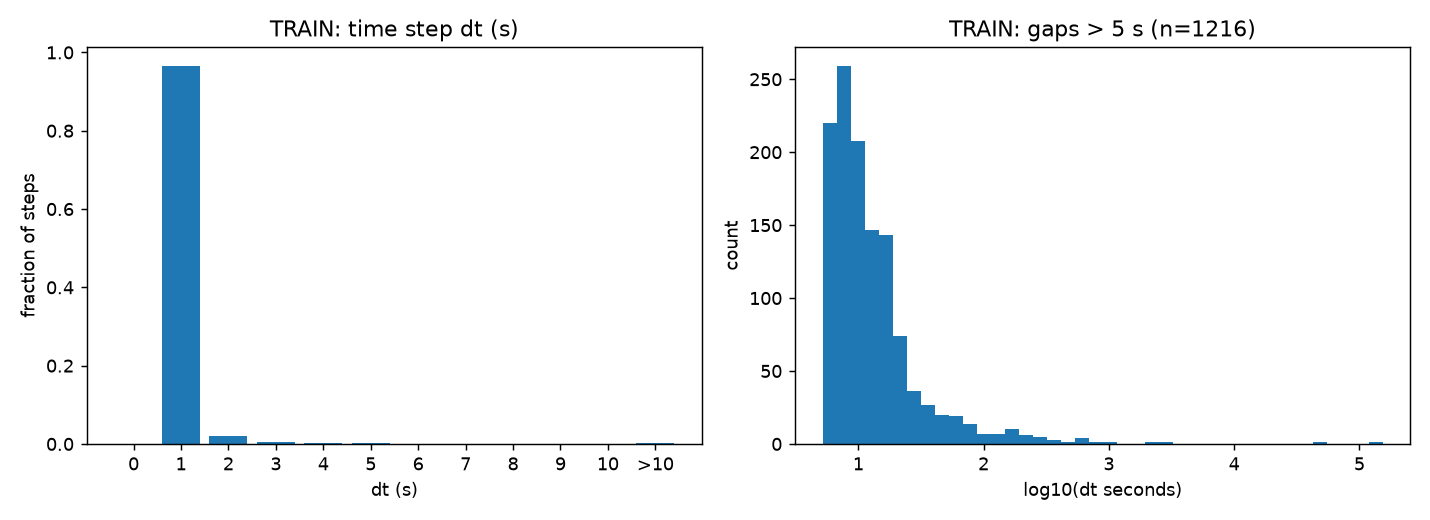

,partition,trip_id,obs_idx,dt_s,jump_m,implied_speed_mps
1200,train,00000090,534,153064.0,3.299719,0.000022
875,train,00000078,1,52810.0,2.523423,0.000048
833,train,00000069,985,2658.0,14.377943,0.005409
451,train,00000021,7868,2161.0,10.054267,0.004653
408,train,00000011,1600,909.0,13.181737,0.014501
832,train,00000069,843,816.0,66.160849,0.081079
713,train,00000042,1891,670.0,1.117306,0.001668
450,train,00000021,183,660.0,19.788953,0.029983


In [6]:
display(Image(FIG / "eda_dt_hist.png"))
gaps = pd.read_csv(RES / "eda_gaps.csv", dtype={"trip_id": str})
gaps.sort_values("dt_s", ascending=False).head(8)

## 4. Speed and jump outliers (TRAIN)

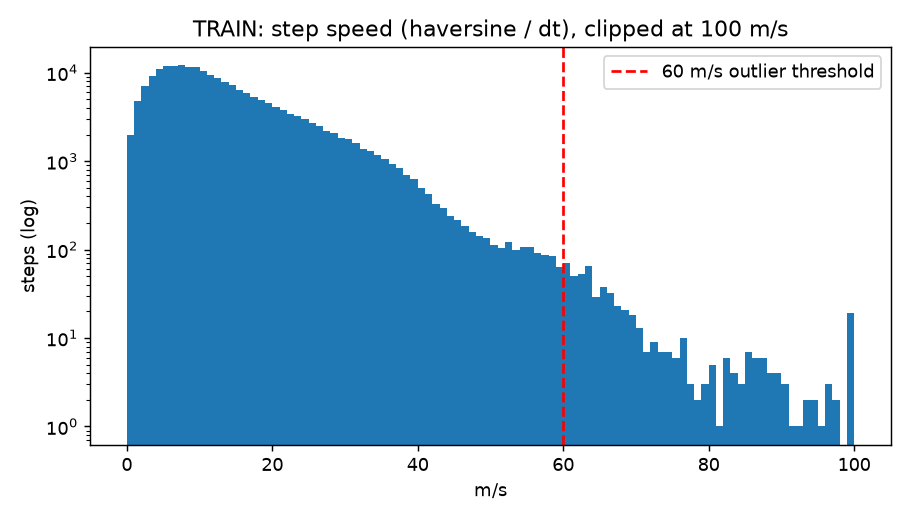

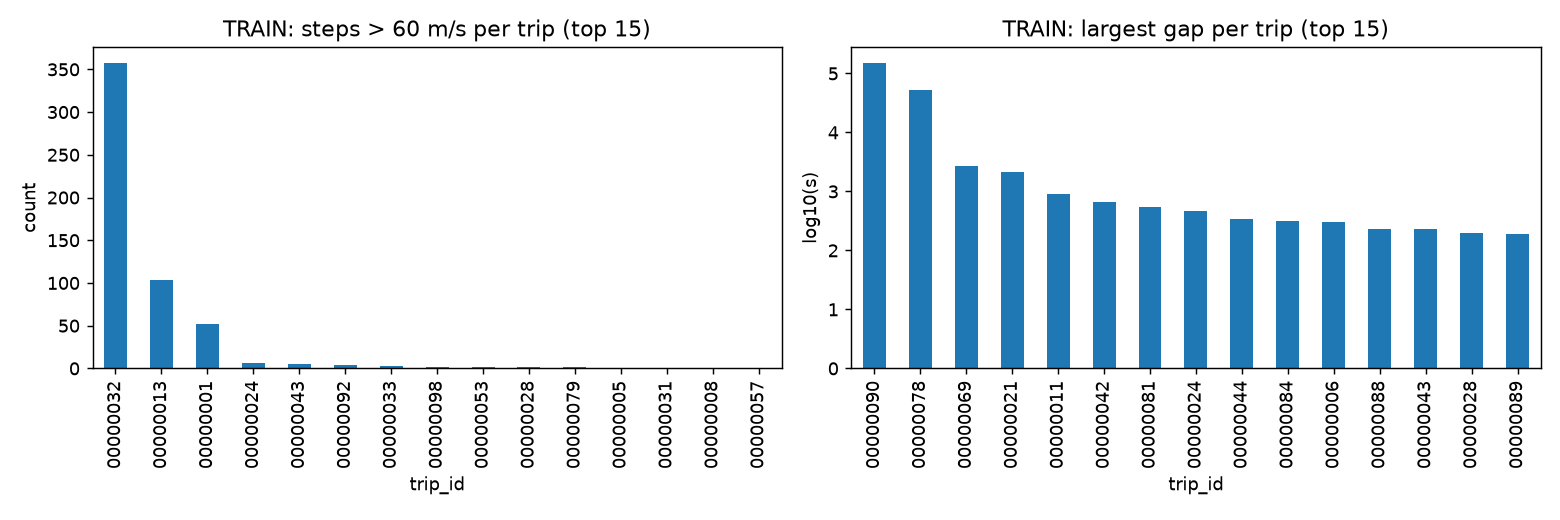

,n,median_speed,max_speed
trip_id,,,
00000032,358,63.861433,83.277530
00000013,103,85.791459,141.543088
00000001,52,62.221824,72.421260
00000024,6,61.231204,65.739037
00000043,5,65.441767,131.663469
00000092,4,74.173292,84.992803
00000033,3,69.006539,141.951109
00000053,2,67.176574,71.186483


In [7]:
display(Image(FIG / "eda_speed_hist.png")); display(Image(FIG / "eda_anomalous_trips.png"))
j = pd.read_csv(RES / "eda_speed_outliers.csv", dtype={"trip_id": str})
j.groupby("trip_id").agg(n=("obs_idx", "size"), median_speed=("speed_mps", "median"), max_speed=("speed_mps", "max")).sort_values("n", ascending=False).head(8)

## 5. Geographic extent and coordinate order
Trips are worldwide (25 UTM zones), so each trip is projected into its own UTM zone. Euclidean distance on degrees is never used.

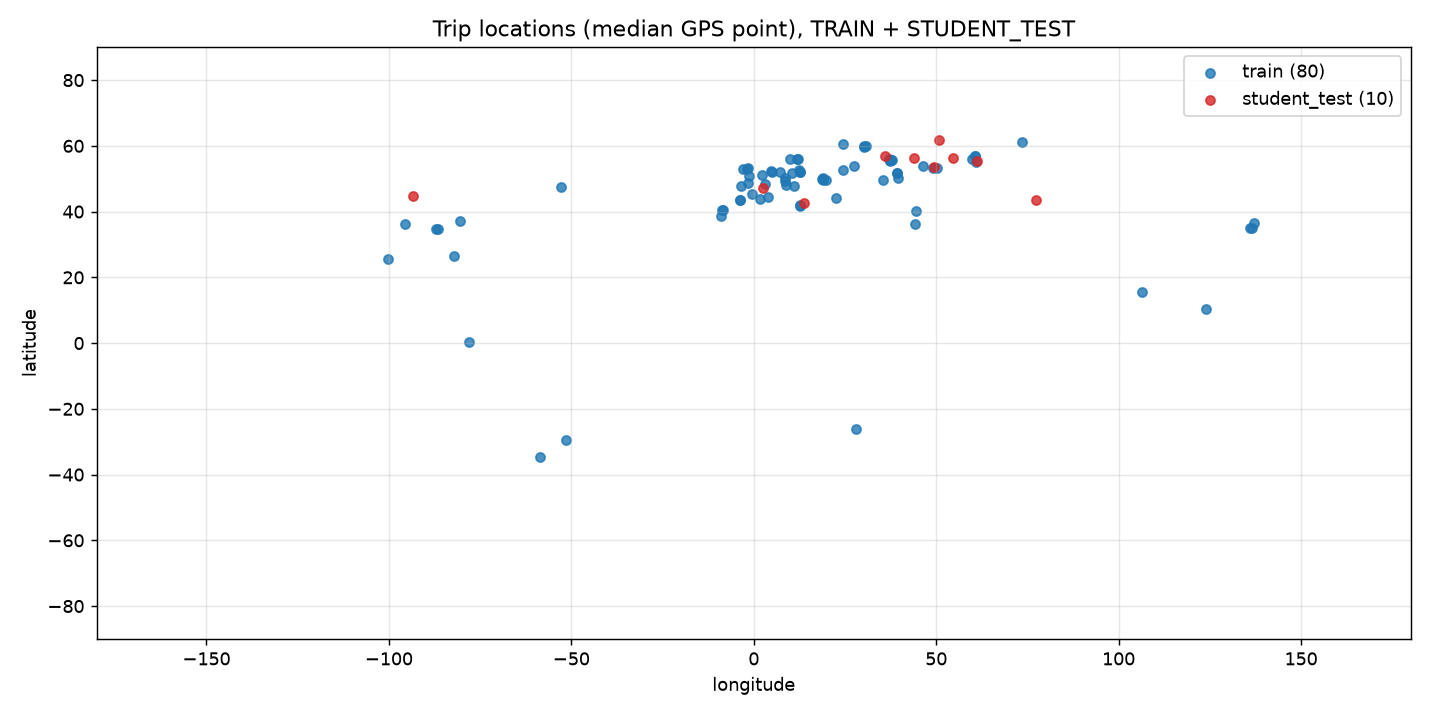

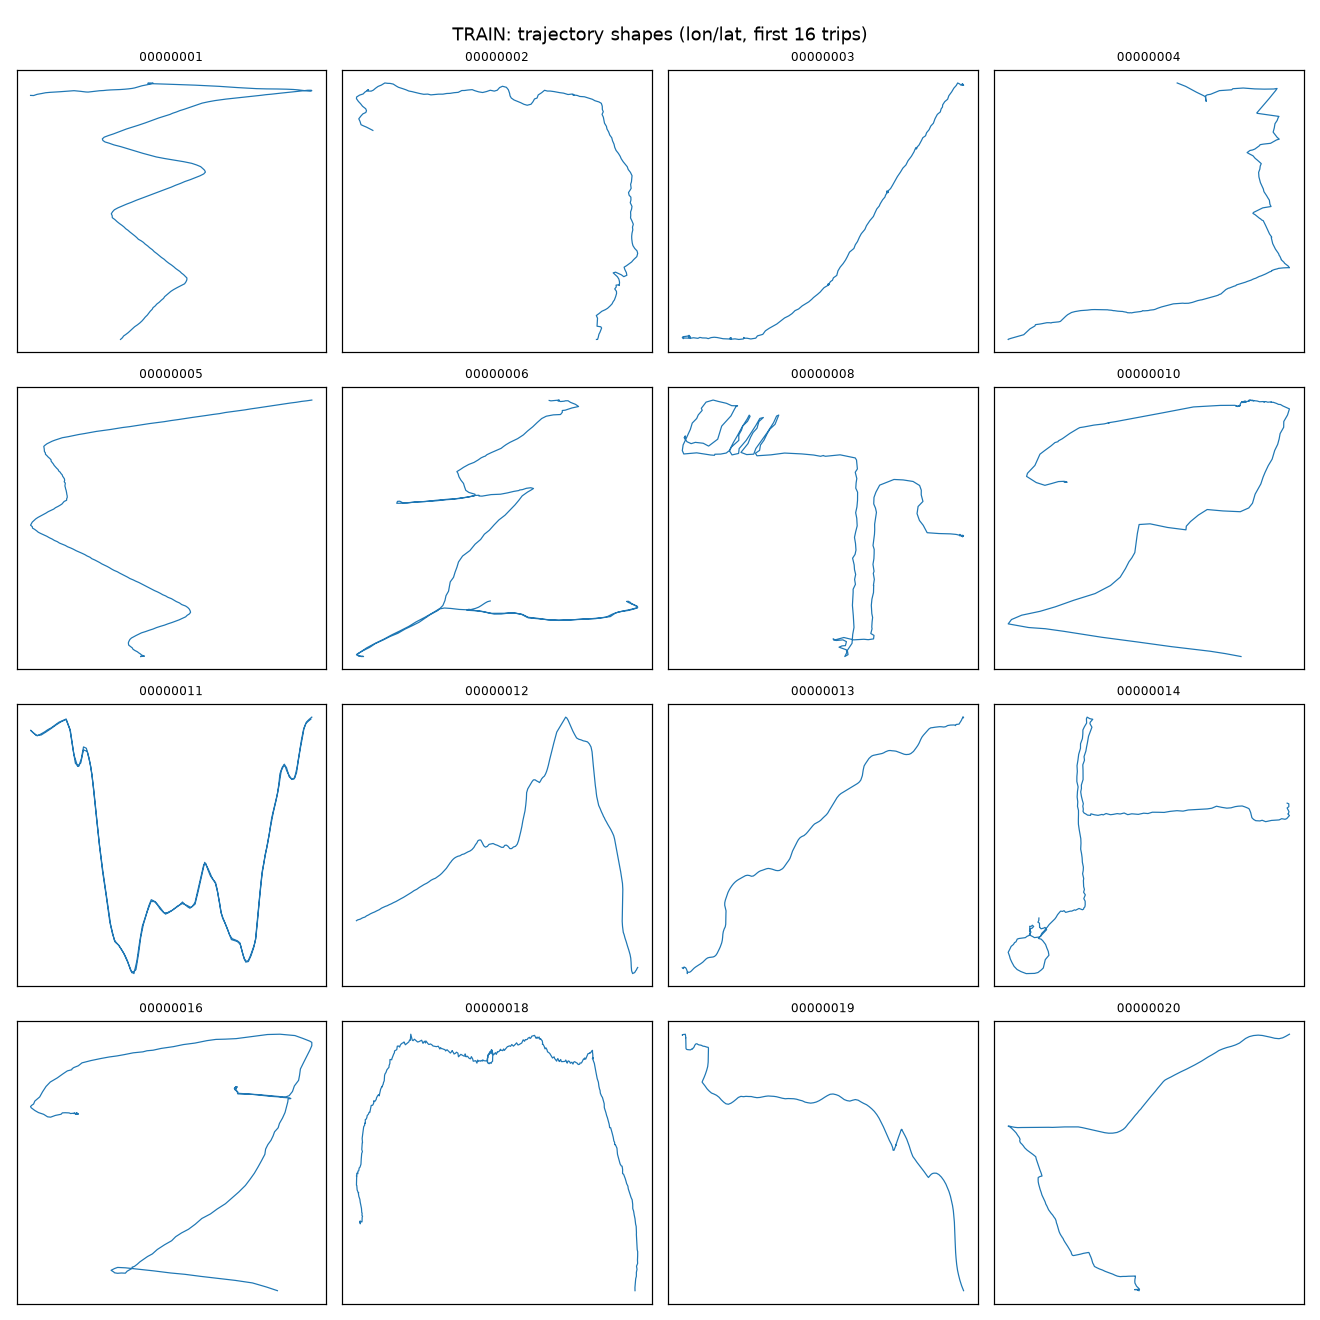

,lon_med,lat_med,utm_epsg,median_nearest_node_m
count,90.00,90.00,90.00,90.00
mean,17.20,45.19,32636.77,22.44
std,47.95,17.60,18.42,17.04
min,-100.36,-34.63,32614.00,7.71
25%,0.05,42.84,32631.00,12.50
50%,16.18,50.22,32634.00,16.58
75%,39.24,55.23,32638.00,23.51
max,137.22,61.67,32735.00,92.90


In [8]:
display(Image(FIG / "eda_trip_locations.png")); display(Image(FIG / "eda_trajectories.png"))
pd.read_csv(RES / "eda_coord_order.csv", dtype={"trip_id": str}).describe().round(2)

## 6. Road networks

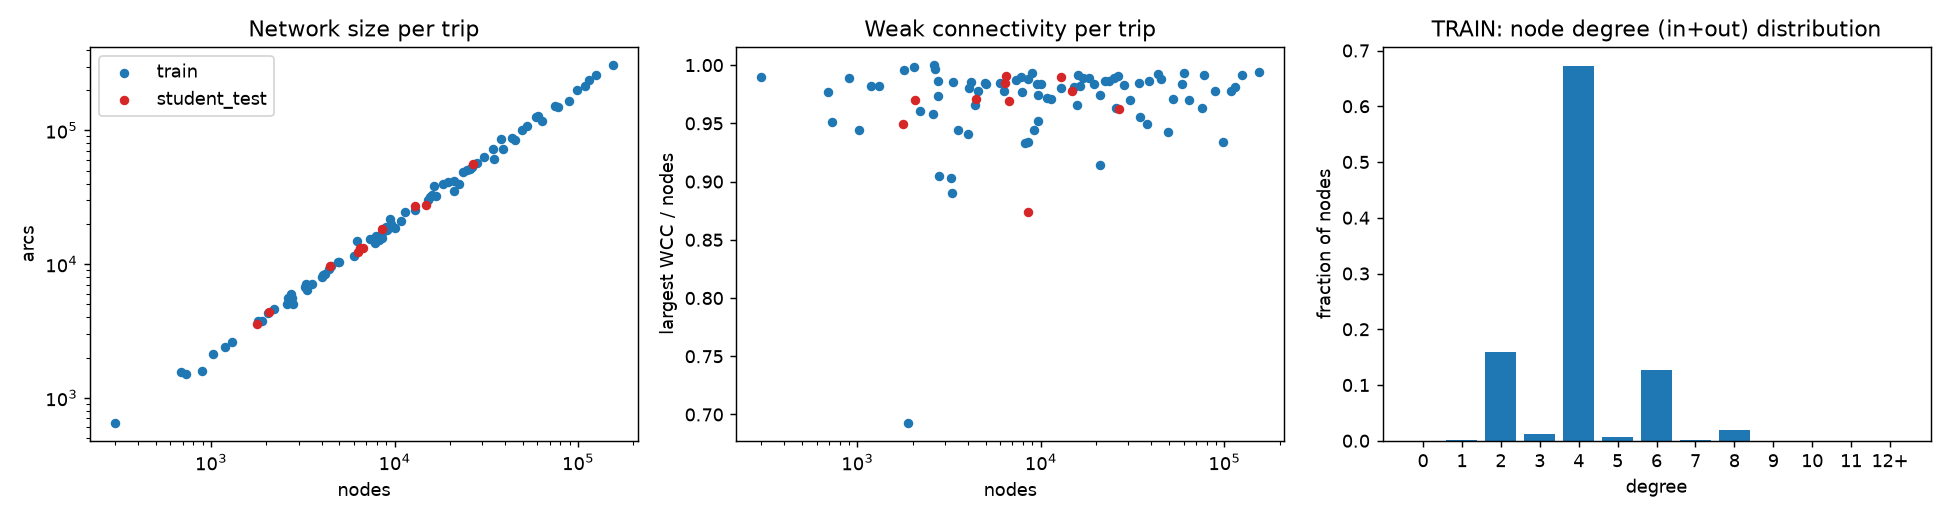

,n_nodes,n_arcs,self_loops,duplicate_arcs,frac_arcs_with_reverse,isolated_nodes,n_weak_components,largest_wcc_frac,largest_scc_frac,arc_len_median_m
count,90.000,90.000,90.000,90.000,90.000,90.0,90.000,90.000,90.000,90.000
mean,22490.822,45132.722,0.267,21.144,0.922,0.0,37.200,0.968,0.949,30.503
std,30868.526,61920.285,1.003,52.017,0.091,0.0,58.149,0.038,0.056,15.336
min,299.000,649.000,0.000,0.000,0.351,0.0,1.000,0.693,0.636,6.751
25%,3655.250,7282.750,0.000,0.000,0.891,0.0,8.250,0.963,0.940,21.315
50%,9305.000,18761.500,0.000,2.500,0.951,0.0,19.000,0.980,0.964,25.142
75%,26296.500,52913.250,0.000,12.000,0.984,0.0,40.750,0.987,0.980,36.103
max,155003.000,307392.000,8.000,322.000,1.000,0.0,421.000,1.000,1.000,85.138


In [9]:
display(Image(FIG / "eda_network.png"))
net = pd.read_csv(RES / "eda_network.csv", dtype={"trip_id": str})
net[["n_nodes", "n_arcs", "self_loops", "duplicate_arcs", "frac_arcs_with_reverse", "isolated_nodes", "n_weak_components", "largest_wcc_frac", "largest_scc_frac", "arc_len_median_m"]].describe().round(3)

## 7. Reference-route structure

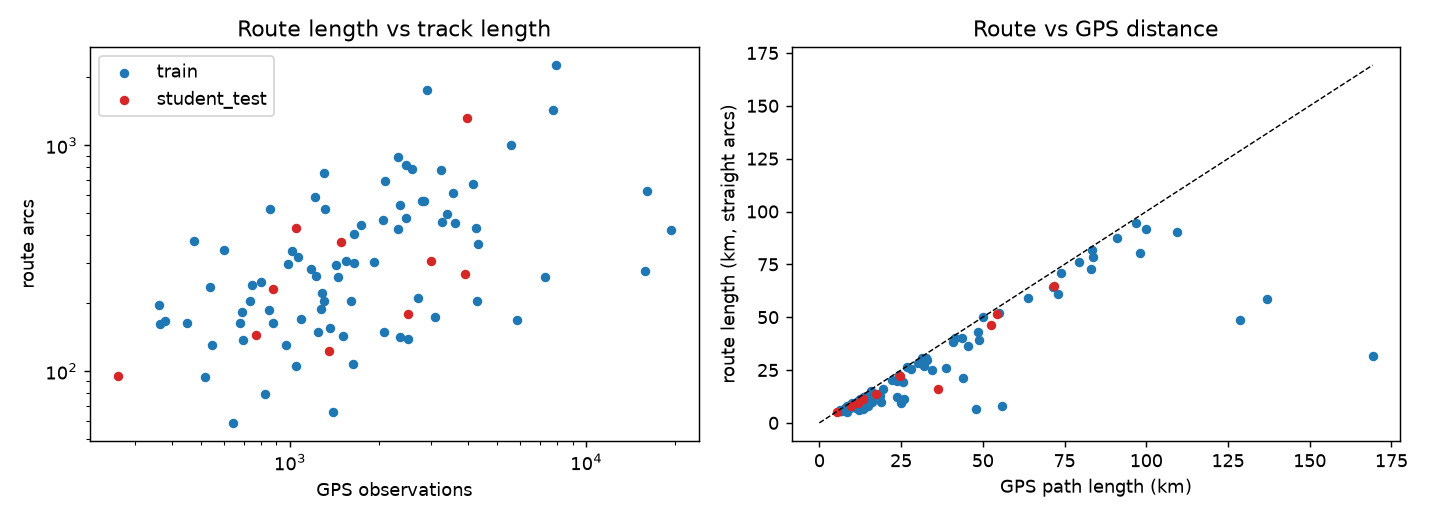

,partition,trip_id,route_len,n_breaks,break_gap_m
1,train,00000002,262,1,324.6
14,train,00000019,545,3,241.6;255.5;597.6
26,train,00000033,169,1,92.0
33,train,00000041,340,1,57.4
34,train,00000042,1440,1,30.7
55,train,00000069,467,1,41.0
60,train,00000075,108,2,10.6;73.1
63,train,00000080,139,1,107.6
69,train,00000086,671,1,97.9
71,train,00000089,265,1,29.4


In [10]:
display(Image(FIG / "eda_route.png"))
route = pd.read_csv(RES / "eda_route.csv", dtype={"trip_id": str})
route[route.n_breaks > 0][["partition", "trip_id", "route_len", "n_breaks", "break_gap_m"]]

## 8. Folium maps
Layers: raw GPS (blue), road network within 200 m of the track (grey), reference route (green), with a layer control and a legend. The HTML files are in `maps/`; the cell below rebuilds them and shows one.

In [11]:
run("scripts/make_maps.py")
IFrame(src="../maps/eda_train_00000072.html", width=950, height=520)

/home/pqtl/ML-Hackathon-148-2026/maps/eda_train_00000072.html  (0.6 MB, 1662 arcs drawn)
/home/pqtl/ML-Hackathon-148-2026/maps/eda_train_00000078.html  (2.0 MB, 10270 arcs drawn)
/home/pqtl/ML-Hackathon-148-2026/maps/eda_train_00000032.html  (1.7 MB, 8313 arcs drawn)
/home/pqtl/ML-Hackathon-148-2026/maps/eda_train_00000013.html  (1.8 MB, 10531 arcs drawn)
/home/pqtl/ML-Hackathon-148-2026/maps/eda_train_00000033.html  (3.0 MB, 1734 arcs drawn)
/home/pqtl/ML-Hackathon-148-2026/maps/eda_student_test_00000056.html  (2.3 MB, 5617 arcs drawn)

